In [ ]:

#bibliotecas para incializar
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

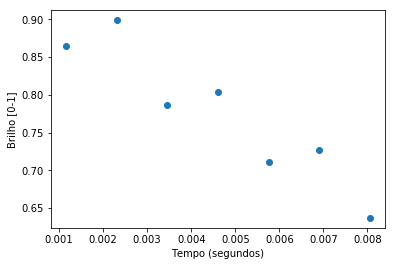

In [2]:
#sinal clássico do fígado
import numpy as np
import matplotlib.pyplot as plt

fatPercent = 0.05

t = [0.0011515,  \
     0.0011515*2,\
     0.0011515*3,\
     0.0011515*4,\
     0.0011515*5,\
     0.0011515*6,\
     0.0011515*7]

rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water

t2star = [0.030,\
          0.040,\
          0.051,\
          0.052,\
          0.062,\
          0.083,\
          0.023]

Fppmn = [5.3,\
         4.2,\
         2.75,\
         2.1,\
         1.3,\
         0.9,\
         4.7]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
t2star = np.array(t2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal) #descobrir o erro no np.absolute
plt.plot(t, Sfinal,'o')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()


In [ ]:
import numpy as np

#calculo dixon
def dixon(s23,s46):
    
    rw = (s46 + s23)/2
    rf = (s46 - s23)/2
         
    ff = rf / (rf + rw)
    
    return(ff)

In [ ]:
from numpy import log,exp

#calculo triplo eco
def tripleEcho(voxelSignal,tEchoes):
    
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    s4 = voxelSignal[3]
    deltaTE = tEchoes[1]-tEchoes[0]
    t2s = deltaTE*log(s2/s4)
    
    rw = (s2 * exp(tEchoes[1]/t2s) + s1* exp(tEchoes[0]/t2s))/2
    rf = (s2 * exp(tEchoes[1]/t2s) - s1* exp(tEchoes[0]/t2s))/2
         
    ff = rf / (rf + rw)
    
    return(ff)

In [ ]:
#importa arquivo csv ImageJ de ROI (#,X,Y,value)
import numpy as np
def import_roi (roi_file):
    roi = np.genfromtxt(roi_file, delimiter=',')
    roi_intensities = roi[1:len(roi),3] #deixa somente as intensidades
    return (roi_intensities)

In [ ]:
#normalize intensities list using Frobenius norm
import numpy as np
def normalize_roi (roi_intensities):
    roi_normalized = roi_intensities/np.linalg.norm (roi_intensities)
    return (roi_normalized, np.linalg.norm (roi_intensities))

In [ ]:
#define pdf for Rice (probability distribution function)
import numpy as np
def func(x, v, s):
    f = (x/s**2)*np.exp(-1*(x**2+v**2)/(2*s**2))*sci.iv(0,x*v/(s**2))
    return f

In [ ]:
#coleta estatisticas da ROI (não utilizado)
import numpy as np
def roi_stats(roi_normalized):
    roi_mean = np.mean(roi_normalized)
    
    roi_variance = np.var(roi_normalized)
    
    roi_histogram = np.histogram(roi_normalized) #check for different bin count methods
    return (roi_mean, roi_variance, roi_histogram)

In [ ]:
#coleta estatisticas da ROI supondo distr. Rayleigh (não utilizado)
import numpy as np
def rayleigh_stats(roi_average, roi_variance):
    rayleigh_mu = 0
    
    rayleigh_sigmaMean = roi_average/np.sqrt(np.pi/2) #calculated from avg
    
    rayleigh_sigmaVar = np.sqrt(2*roi_variance/(4-np.pi)) #calculated from var
    
    return (rayleigh_mu, rayleigh_sigmaMean, rayleigh_sigmaVar)

In [ ]:
#coleta estatisticas da ROI supondo distr. Gaussiana (não utilizado)
import numpy as np
def gauss_stats(roi_average, roi_variance):
    gauss_mu = roi_average
    
    gauss_sigma = np.sqrt(roi_variance)
    
    return (gauss_mu, gauss_sigma)